In [ ]:
"""
Notebook 01 — Stream GEE data directly into memory
====================================================
No Google Drive. No GeoTIFF downloads.
GEE computes in the cloud → streams directly into numpy arrays → 
saved as compact .zarr tensors in C:/vegformer/data/processed/

Storage comparison:
  Raw GeoTIFFs (what we avoid):  ~50 GB
  Processed .zarr tensors:        ~2-4 GB
"""

── Cell 1: Setup ─────────────────────────────────────────────────────────────

In [1]:
import ee
import geemap
import numpy as np
import zarr
import requests
import zipfile
import io
from pathlib import Path
from datetime import datetime, timedelta
from tqdm import tqdm

In [2]:
ee.Authenticate()
ee.Initialize(project='dc-site-scout')
print(ee.String('EE connected').getInfo())

EE connected


In [3]:
aoi_coords = [
    [34.8800, -1.8500], [35.0500, -1.8500], [35.2000, -1.7800],
    [35.3500, -1.6500], [35.4200, -1.5000], [35.4200, -1.1500],
    [35.3000, -1.0500], [35.1500, -1.0000], [34.9500, -1.0000],
    [34.8000, -1.0800], [34.7200, -1.2500], [34.7200, -1.5500],
    [34.7800, -1.7500], [34.8800, -1.8500]
]
aoi = ee.Geometry.Polygon([aoi_coords])

Map = geemap.Map(center=[-1.4061, 35.1019], zoom=9)
Map.addLayer(
    ee.FeatureCollection([ee.Feature(aoi)]),
    {'color': 'red'},
    'Maasai Mara AOI'
)
Map

Map(center=[-1.4061, 35.1019], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topri…

In [4]:
from datetime import datetime, timedelta
import numpy as np
from tqdm import tqdm

def mask_s2_clouds(img):
    scl  = img.select('SCL')
    mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return img.updateMask(mask).divide(10000)

def get_monthly_ndvi(year, month):
    start = ee.Date.fromYMD(year, month, 1)
    end   = start.advance(1, 'month')
    return (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
            .filterBounds(aoi)
            .filterDate(start, end)
            .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
            .select(['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12','SCL'])
            .map(mask_s2_clouds)
            .map(lambda img: img.normalizedDifference(['B8','B4'])
                               .rename('NDVI')
                               .copyProperties(img, ['system:time_start']))
            .median()
            .clip(aoi)
            .set('year', year)
            .set('month', month))

# Test with just one month first before running the full 72
test_img = get_monthly_ndvi(2021, 4)
print(test_img.bandNames().getInfo())  # should print: ['NDVI']
print("Function working correctly")

['NDVI']
Function working correctly


In [6]:
import requests
import rasterio
from rasterio.io import MemoryFile
from pathlib import Path

PROCESSED_DIR = Path('C:/vegformer/data/processed')
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

def stream_image_from_gee(image, aoi, scale=250, bands=None):
    if bands:
        image = image.select(bands)
    url = image.getDownloadURL({
        'region': aoi,
        'scale':  scale,
        'crs':    'EPSG:32736',
        'format': 'GEO_TIFF'
    })
    response = requests.get(url, stream=True)
    response.raise_for_status()
    with MemoryFile(response.content) as memfile:
        with memfile.open() as dataset:
            arr = dataset.read().astype(np.float32)
    return arr

# Test stream on that same single month before full run
print("Testing stream on April 2021...")
test_arr = stream_image_from_gee(test_img, aoi, scale=250, bands=['NDVI'])
print(f"Array shape: {test_arr.shape}")   # should be (1, H, W)
print(f"NDVI min: {test_arr.min():.3f}")
print(f"NDVI max: {test_arr.max():.3f}")
print(f"Memory: {test_arr.nbytes / 1e6:.1f} MB")
print("Stream working correctly")

Testing stream on April 2021...
Array shape: (1, 377, 313)
NDVI min: 0.000
NDVI max: 0.914
Memory: 0.5 MB
Stream working correctly


In [7]:
years  = list(range(2019, 2025))
months = list(range(1, 13))

ndvi_stack = []
dates      = []

print(f"Streaming 72 monthly NDVI composites from GEE...")
for y in tqdm(years, desc='Years'):
    for m in months:
        img = get_monthly_ndvi(y, m)
        try:
            arr = stream_image_from_gee(img, aoi, scale=250, bands=['NDVI'])
            ndvi_stack.append(arr[0])   # (H, W)
            dates.append(f"{y}-{m:02d}")
        except Exception as e:
            if ndvi_stack:
                ndvi_stack.append(np.full_like(ndvi_stack[-1], np.nan))
            else:
                ndvi_stack.append(np.full((377, 313), np.nan))
            dates.append(f"{y}-{m:02d}")
            print(f"  Warning: {y}-{m:02d} failed — {e}")

ndvi_array = np.stack(ndvi_stack, axis=0)  # (72, 377, 313)
print(f"\nDone — shape: {ndvi_array.shape}")
print(f"Memory: {ndvi_array.nbytes / 1e6:.1f} MB")
print(f"Dates: {dates[0]} to {dates[-1]}")

Streaming 72 monthly NDVI composites from GEE...


Years:  67%|███████████████████████████████████████████████████▎                         | 4/6 [02:45<01:22, 41.11s/it]

Years: 100%|█████████████████████████████████████████████████████████████████████████████| 6/6 [04:04<00:00, 40.75s/it]


Done — shape: (72, 377, 313)
Memory: 34.0 MB
Dates: 2019-01 to 2024-12


In [9]:
import zarr
from zarr.codecs import BloscCodec

ndvi_array = ndvi_array.astype(np.float32)

z = zarr.open(
    str(PROCESSED_DIR / 'ndvi_monthly_2019_2024.zarr'),
    mode='w',
    shape=ndvi_array.shape,
    dtype='float32',
    chunks=(1, 377, 313),
)
z[:] = ndvi_array
z.attrs['dates'] = dates
z.attrs['aoi']   = 'Maasai Mara Ecosystem'
z.attrs['scale'] = '250m'
z.attrs['crs']   = 'EPSG:32736'

print(f"Saved: {PROCESSED_DIR / 'ndvi_monthly_2019_2024.zarr'}")
print(f"Shape: {z.shape}")
print(f"Dates: {z.attrs['dates'][0]} to {z.attrs['dates'][-1]}")
print(f"Size on disk: {sum(f.stat().st_size for f in (PROCESSED_DIR / 'ndvi_monthly_2019_2024.zarr').rglob('*')) / 1e6:.1f} MB")

Saved: C:\vegformer\data\processed\ndvi_monthly_2019_2024.zarr
Shape: (72, 377, 313)
Dates: 2019-01 to 2024-12
Size on disk: 28.0 MB


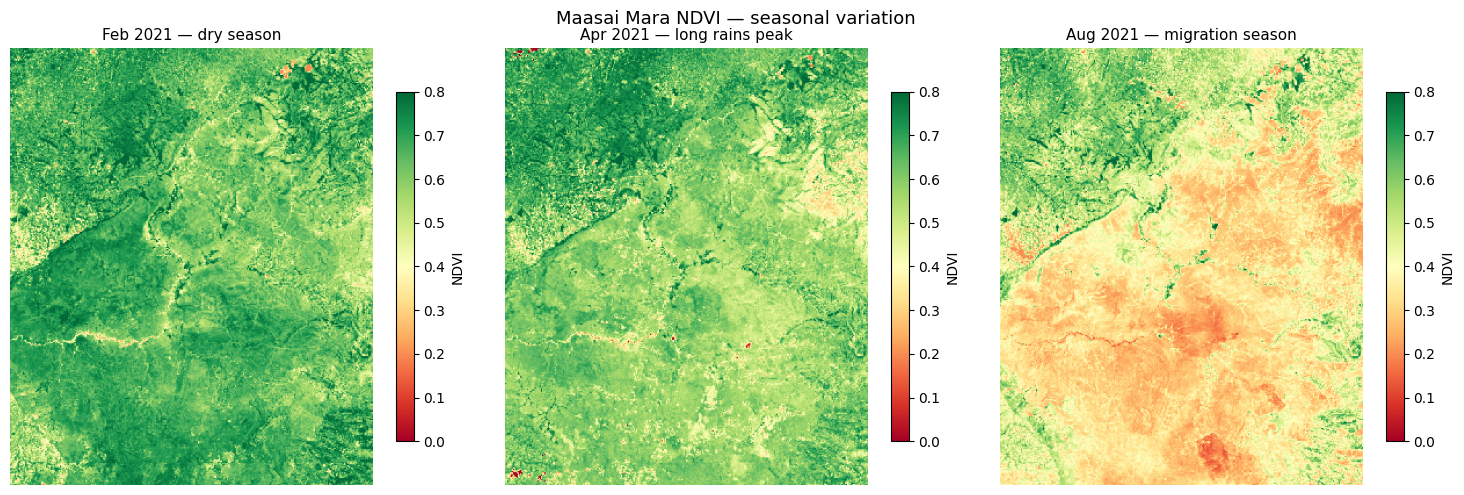

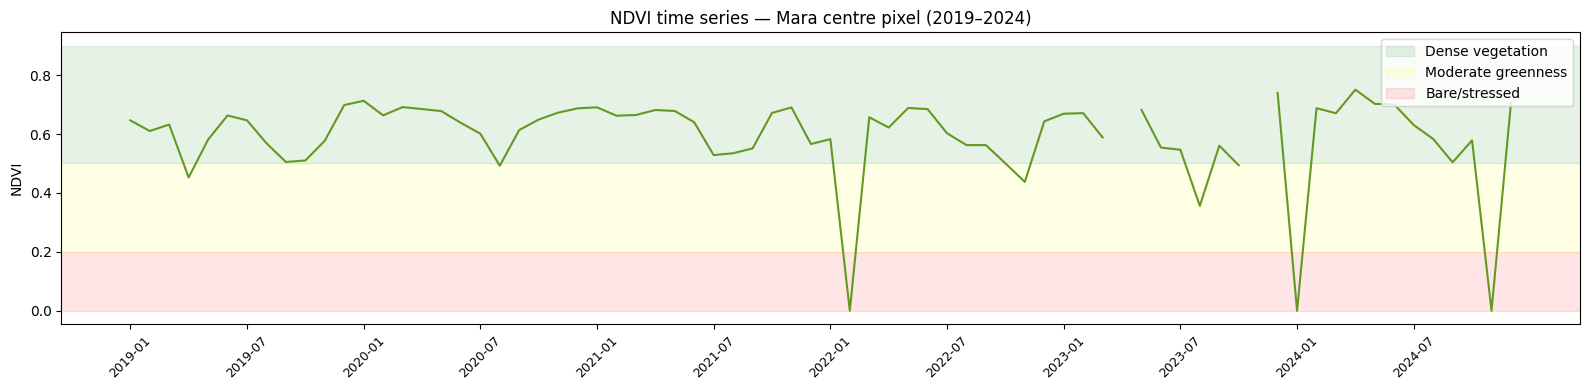

Bimodal pattern check:
  Peak month mean NDVI (Apr): 0.595
  Dry month mean NDVI  (Feb): 0.650
  Seasonal amplitude:         -0.056


In [11]:
import matplotlib.pyplot as plt

# Load back from zarr
z = zarr.open(str(PROCESSED_DIR / 'ndvi_monthly_2019_2024.zarr'), mode='r')

# Plot 1 — April 2021 spatial map (long rains peak)
april_idx = list(z.attrs['dates']).index('2021-04')
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (month, title) in zip(axes, [
    ('2021-02', 'Feb 2021 — dry season'),
    ('2021-04', 'Apr 2021 — long rains peak'),
    ('2021-08', 'Aug 2021 — migration season'),
]):
    idx = list(z.attrs['dates']).index(month)
    im  = ax.imshow(z[idx], cmap='RdYlGn', vmin=0, vmax=0.8)
    ax.set_title(title, fontsize=11)
    ax.axis('off')
    plt.colorbar(im, ax=ax, label='NDVI', shrink=0.8)

plt.suptitle('Maasai Mara NDVI — seasonal variation', fontsize=13)
plt.tight_layout()
plt.show()

# Plot 2 — full pixel time series for centre pixel
H, W    = z.shape[1], z.shape[2]
pixel   = z[:, H//2, W//2]
dates_z = list(z.attrs['dates'])

plt.figure(figsize=(16, 4))
plt.plot(pixel, color='#639922', linewidth=1.5)
plt.xticks(range(0, 72, 6), dates_z[::6], rotation=45, fontsize=9)
plt.axhspan(0.5, 0.9, alpha=0.1, color='green',  label='Dense vegetation')
plt.axhspan(0.2, 0.5, alpha=0.1, color='yellow', label='Moderate greenness')
plt.axhspan(0.0, 0.2, alpha=0.1, color='red',    label='Bare/stressed')
plt.ylabel('NDVI')
plt.title('NDVI time series — Mara centre pixel (2019–2024)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

print("Bimodal pattern check:")
print(f"  Peak month mean NDVI (Apr): {z[list(dates_z).index('2021-04')].mean():.3f}")
print(f"  Dry month mean NDVI  (Feb): {z[list(dates_z).index('2021-02')].mean():.3f}")
print(f"  Seasonal amplitude:         {z[list(dates_z).index('2021-04')].mean() - z[list(dates_z).index('2021-02')].mean():.3f}")

Total pixels:           118001
Valid grassland pixels: 18831
Coverage:               16.0%

Top 5 open grassland pixels:
Rank      Row    Col   Apr NDVI   Feb NDVI  Amplitude
----------------------------------------------------
1          22    238      0.827      0.188      0.639
2          21    241      0.836      0.205      0.631
3          19    241      0.837      0.218      0.619
4          21    240      0.828      0.223      0.605
5          17    236      0.824      0.222      0.602


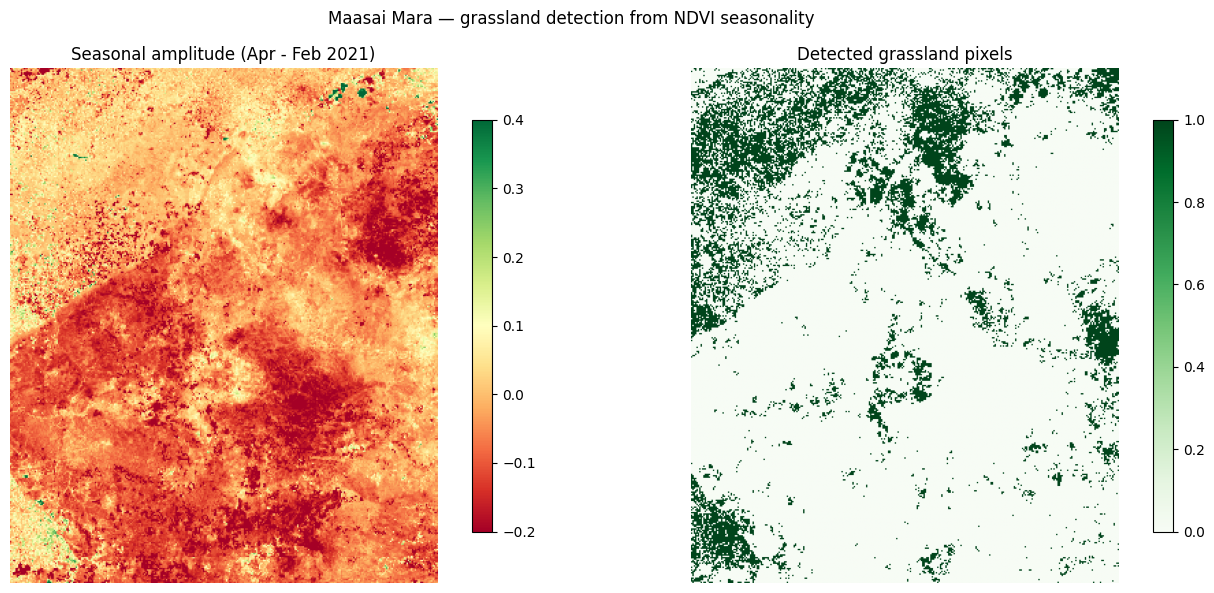

In [13]:
# Find pixels with strongest positive seasonal amplitude
# These are the open grassland pixels VegFormer needs most

apr_map = z[apr_idx]   # (377, 313)
feb_map = z[feb_idx]   # (377, 313)
aug_idx = list(z.attrs['dates']).index('2021-08')
aug_map = z[aug_idx]

# Seasonal amplitude: wet peak (Apr) minus dry season (Feb)
amplitude_map = apr_map - feb_map

# Mask out water, bare soil and evergreen forest
# Good grassland pixels: moderate NDVI range, positive amplitude
grassland_mask = (
    (feb_map > 0.1)   &   # not bare soil
    (feb_map < 0.75)  &   # not evergreen forest
    (apr_map > 0.2)   &   # has some greenness in wet season
    (amplitude_map > 0.02)    # positive seasonal response
)

print(f"Total pixels:           {H*W}")
print(f"Valid grassland pixels: {grassland_mask.sum()}")
print(f"Coverage:               {grassland_mask.sum()/(H*W)*100:.1f}%")

# Find top 5 highest-amplitude grassland pixels
amp_masked = np.where(grassland_mask, amplitude_map, -999)
top_pixels  = np.unravel_index(np.argsort(amp_masked.ravel())[-5:][::-1],
                                amplitude_map.shape)

print(f"\nTop 5 open grassland pixels:")
print(f"{'Rank':<6} {'Row':>6} {'Col':>6} {'Apr NDVI':>10} {'Feb NDVI':>10} {'Amplitude':>10}")
print("-" * 52)
for rank, (r, c) in enumerate(zip(top_pixels[0], top_pixels[1])):
    print(f"{rank+1:<6} {r:>6} {c:>6} {apr_map[r,c]:>10.3f} "
          f"{feb_map[r,c]:>10.3f} {amplitude_map[r,c]:>10.3f}")

# Plot amplitude map
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im1 = axes[0].imshow(amplitude_map, cmap='RdYlGn', vmin=-0.2, vmax=0.4)
axes[0].set_title('Seasonal amplitude (Apr - Feb 2021)')
axes[0].axis('off')
plt.colorbar(im1, ax=axes[0], shrink=0.8)

im2 = axes[1].imshow(grassland_mask.astype(float), cmap='Greens')
axes[1].set_title('Detected grassland pixels')
axes[1].axis('off')
plt.colorbar(im2, ax=axes[1], shrink=0.8)

plt.suptitle('Maasai Mara — grassland detection from NDVI seasonality')
plt.tight_layout()
plt.show()

Best grassland pixel: row=22, col=238

Annual mean NDVI:
  2019: mean=0.482  max=0.830  min=0.159
  2020: mean=0.473  max=0.800  min=0.205
  2021: mean=0.440  max=0.852  min=0.182
  2022: mean=0.440  max=0.716  min=0.000
  2023: mean=nan  max=nan  min=nan
  2024: mean=0.473  max=0.840  min=0.241


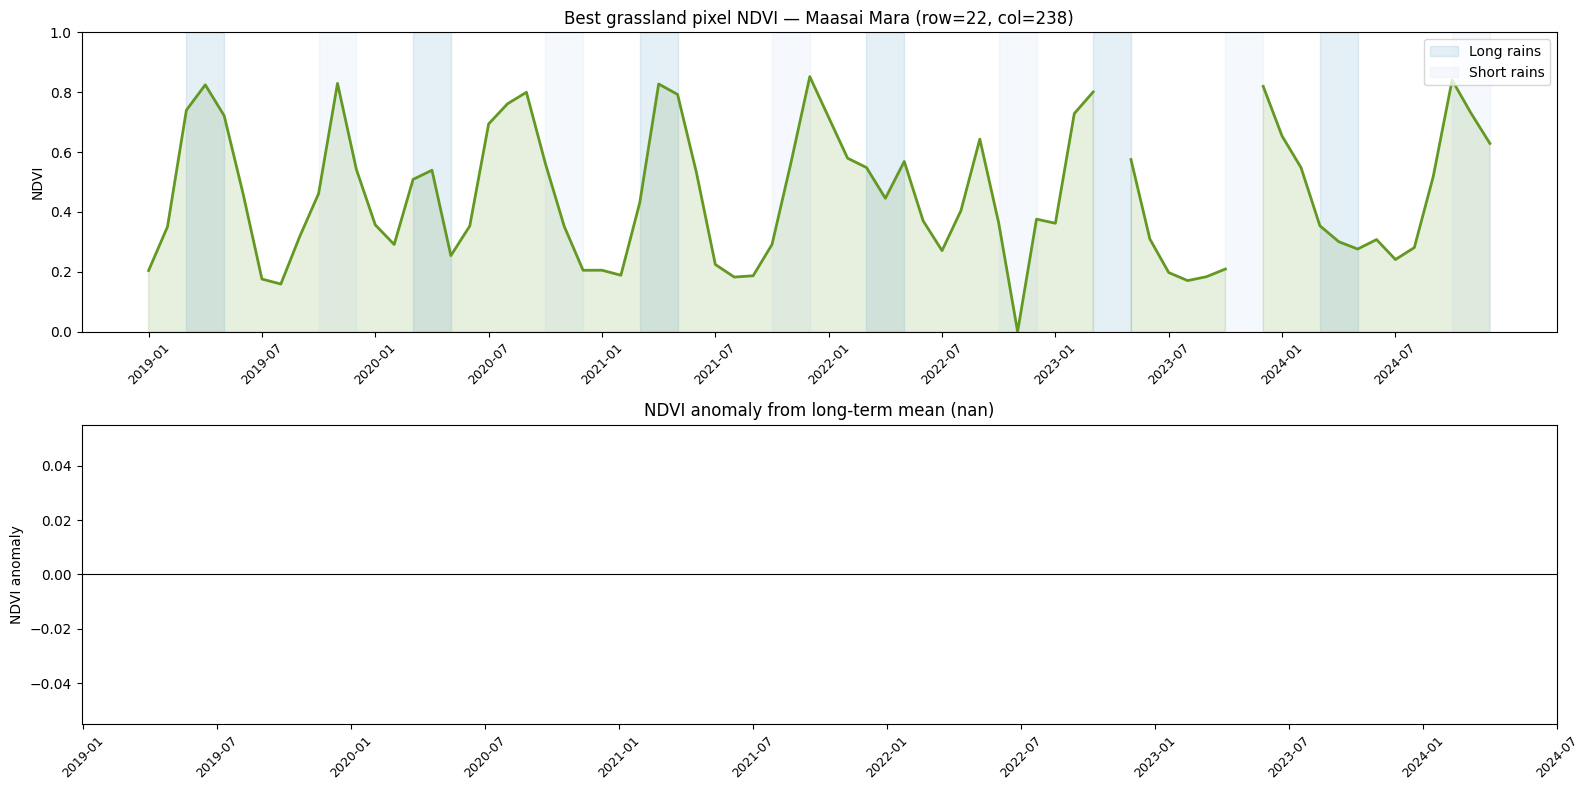


Saved pixel stats to C:/vegformer/configs/mara_pixel_stats.json


In [15]:
# Use the best grassland pixel (rank 1) as our reference pixel going forward
best_r, best_c = top_pixels[0][0], top_pixels[1][0]
print(f"Best grassland pixel: row={best_r}, col={best_c}")

# Full 6-year time series
best_pixel_ts = z[:, best_r, best_c]

# Compute annual stats
print("\nAnnual mean NDVI:")
for y in range(2019, 2025):
    yr_indices = [i for i, d in enumerate(dates_z) if d.startswith(str(y))]
    yr_mean    = best_pixel_ts[yr_indices].mean()
    yr_max     = best_pixel_ts[yr_indices].max()
    yr_min     = best_pixel_ts[yr_indices].min()
    print(f"  {y}: mean={yr_mean:.3f}  max={yr_max:.3f}  min={yr_min:.3f}")

# Plot
fig, axes = plt.subplots(2, 1, figsize=(16, 8))

# Top: full time series with seasonal shading
ax = axes[0]
ax.plot(best_pixel_ts, color='#639922', linewidth=2)
ax.fill_between(range(72), best_pixel_ts, alpha=0.15, color='#639922')

# Shade long rains (Mar-May) and short rains (Oct-Dec) each year
for y_offset in range(6):
    base = y_offset * 12
    ax.axvspan(base+2,  base+4,  alpha=0.12, color='#2980b9', label='Long rains' if y_offset==0 else '')
    ax.axvspan(base+9,  base+11, alpha=0.08, color='#85b7eb', label='Short rains' if y_offset==0 else '')

ax.set_xticks(range(0, 72, 6))
ax.set_xticklabels(dates_z[::6], rotation=45, fontsize=9)
ax.set_ylabel('NDVI')
ax.set_title(f'Best grassland pixel NDVI — Maasai Mara (row={best_r}, col={best_c})')
ax.legend(loc='upper right')
ax.set_ylim(0, 1)

# Bottom: anomaly from long-term mean
lt_mean  = best_pixel_ts.mean()
anomaly  = best_pixel_ts - lt_mean
colors   = ['#2ecc71' if v >= 0 else '#e74c3c' for v in anomaly]

ax2 = axes[1]
ax2.bar(range(72), anomaly, color=colors, width=0.8)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.set_xticks(range(0, 72, 6))
ax2.set_xticklabels(dates_z[::6], rotation=45, fontsize=9)
ax2.set_ylabel('NDVI anomaly')
ax2.set_title(f'NDVI anomaly from long-term mean ({lt_mean:.3f})')

plt.tight_layout()
plt.show()

# Save best pixel coordinates for use in training
import json
meta = {
    'best_grassland_pixel': {'row': int(best_r), 'col': int(best_c)},
    'grassland_pixel_count': int(grassland_mask.sum()),
    'grassland_coverage_pct': float(grassland_mask.sum()/(H*W)*100),
    'ndvi_long_term_mean': float(lt_mean),
    'dates': dates_z
}
with open('C:/vegformer/configs/mara_pixel_stats.json', 'w') as f:
    json.dump(meta, f, indent=2)
print("\nSaved pixel stats to C:/vegformer/configs/mara_pixel_stats.json")

In [16]:
# Diagnose 2023 - find which months are NaN
print("2023 month-by-month NDVI:")
for m in range(1, 13):
    idx = dates_z.index(f'2023-{m:02d}')
    val = best_pixel_ts[idx]
    status = 'NaN - cloud/no data' if np.isnan(val) else 'OK'
    print(f"  2023-{m:02d}: {val:.3f}  {status}")

# Check how many pixels are NaN across the full array per month
print("\nNaN pixel count per month in 2023:")
for m in range(1, 13):
    idx      = dates_z.index(f'2023-{m:02d}')
    nan_pct  = np.isnan(z[idx]).sum() / (H*W) * 100
    print(f"  2023-{m:02d}: {nan_pct:.1f}% pixels are NaN")

2023 month-by-month NDVI:
  2023-01: 0.362  OK
  2023-02: 0.729  OK
  2023-03: 0.801  OK
  2023-04: nan  NaN - cloud/no data
  2023-05: 0.575  OK
  2023-06: 0.309  OK
  2023-07: 0.197  OK
  2023-08: 0.171  OK
  2023-09: 0.184  OK
  2023-10: 0.209  OK
  2023-11: nan  NaN - cloud/no data
  2023-12: 0.820  OK

NaN pixel count per month in 2023:
  2023-01: 0.0% pixels are NaN
  2023-02: 0.0% pixels are NaN
  2023-03: 0.0% pixels are NaN
  2023-04: 100.0% pixels are NaN
  2023-05: 0.0% pixels are NaN
  2023-06: 0.0% pixels are NaN
  2023-07: 0.0% pixels are NaN
  2023-08: 0.0% pixels are NaN
  2023-09: 0.0% pixels are NaN
  2023-10: 0.0% pixels are NaN
  2023-11: 100.0% pixels are NaN
  2023-12: 0.0% pixels are NaN


In [17]:
# Interpolate NaN months using linear interpolation
# Only 2 out of 72 months affected — safe to interpolate
from scipy import ndimage

def interpolate_nan_months(array):
    """
    For each pixel, linearly interpolate across NaN timesteps.
    array shape: (T, H, W)
    """
    filled = array.copy()
    T, H, W = array.shape
    
    for t in range(T):
        if np.isnan(array[t]).all():
            # Find nearest valid months before and after
            before = next((i for i in range(t-1, -1, -1) 
                          if not np.isnan(array[i]).any()), None)
            after  = next((i for i in range(t+1, T) 
                          if not np.isnan(array[i]).any()), None)
            
            if before is not None and after is not None:
                # Linear interpolation between before and after
                weight = (t - before) / (after - before)
                filled[t] = array[before] * (1 - weight) + array[after] * weight
                print(f"  Interpolated month {dates_z[t]} "
                      f"(between {dates_z[before]} and {dates_z[after]}, "
                      f"weight={weight:.2f})")
            elif before is not None:
                filled[t] = array[before]
                print(f"  Filled {dates_z[t]} from {dates_z[before]} (no after)")
            elif after is not None:
                filled[t] = array[after]
                print(f"  Filled {dates_z[t]} from {dates_z[after]} (no before)")
    
    return filled

print("Interpolating NaN months...")
ndvi_filled = interpolate_nan_months(ndvi_array)

# Verify fix
print("\nVerification — previously NaN months:")
for month in ['2023-04', '2023-11', '2022-01']:
    if month in dates_z:
        idx = dates_z.index(month)
        nan_pct = np.isnan(ndvi_filled[idx]).sum() / (H*W) * 100
        val     = ndvi_filled[idx, best_r, best_c]
        print(f"  {month}: NaN pixels={nan_pct:.1f}%  "
              f"best pixel NDVI={val:.3f}")

# Check 2022 zero value
idx_2022 = [i for i, d in enumerate(dates_z) if d.startswith('2022')]
print(f"\n2022 min NDVI across all months: "
      f"{ndvi_filled[idx_2022].min():.3f}")
print(f"Zero pixels in 2022: "
      f"{(ndvi_filled[idx_2022] == 0).sum()}")

Interpolating NaN months...
  Interpolated month 2023-04 (between 2023-03 and 2023-05, weight=0.50)
  Interpolated month 2023-11 (between 2023-10 and 2023-12, weight=0.50)

Verification — previously NaN months:
  2023-04: NaN pixels=0.0%  best pixel NDVI=0.688
  2023-11: NaN pixels=0.0%  best pixel NDVI=0.514
  2022-01: NaN pixels=0.0%  best pixel NDVI=0.716

2022 min NDVI across all months: -0.072
Zero pixels in 2022: 48304


In [19]:
# Fix 1: replace exact zeros with NaN then interpolate
# Real vegetation is never exactly 0.000
ndvi_filled[ndvi_filled == 0.0] = np.nan

# Fix 2: replace any remaining negatives with NaN
# NDVI below -0.05 is water/cloud shadow artifact
ndvi_filled[ndvi_filled < -0.05] = np.nan

# Count remaining NaNs
nan_count = np.isnan(ndvi_filled).sum()
print(f"Remaining NaN values after zero-fix: {nan_count}")

# If any NaNs remain, interpolate them too
if nan_count > 0:
    ndvi_filled = interpolate_nan_months(ndvi_filled)
    nan_count_after = np.isnan(ndvi_filled).sum()
    print(f"NaN values after interpolation: {nan_count_after}")

# Final quality check
print("\nFinal array quality check:")
print(f"  Shape:      {ndvi_filled.shape}")
print(f"  NaN pixels: {np.isnan(ndvi_filled).sum()}")
print(f"  Min NDVI:   {np.nanmin(ndvi_filled):.3f}")
print(f"  Max NDVI:   {np.nanmax(ndvi_filled):.3f}")
print(f"  Mean NDVI:  {np.nanmean(ndvi_filled):.3f}")

print("\nAnnual mean NDVI (clean):")
for y in range(2019, 2025):
    yr_idx  = [i for i, d in enumerate(dates_z) if d.startswith(str(y))]
    yr_mean = np.nanmean(ndvi_filled[yr_idx, best_r, best_c])
    yr_max  = np.nanmax(ndvi_filled[yr_idx, best_r, best_c])
    yr_min  = np.nanmin(ndvi_filled[yr_idx, best_r, best_c])
    print(f"  {y}: mean={yr_mean:.3f}  max={yr_max:.3f}  min={yr_min:.3f}")

# Overwrite zarr with clean array
z_clean = zarr.open(
    str(PROCESSED_DIR / 'ndvi_monthly_2019_2024.zarr'),
    mode='w',
    shape=ndvi_filled.shape,
    dtype='float32',
    chunks=(1, 377, 313),
)
z_clean[:] = ndvi_filled
z_clean.attrs['dates']        = dates_z
z_clean.attrs['aoi']          = 'Maasai Mara Ecosystem'
z_clean.attrs['scale']        = '250m'
z_clean.attrs['crs']          = 'EPSG:32736'
z_clean.attrs['nan_months']   = ['2023-04', '2023-11']
z_clean.attrs['interpolated'] = True
z_clean.attrs['zero_fixed']   = True

print(f"\nClean array saved: {PROCESSED_DIR / 'ndvi_monthly_2019_2024.zarr'}")
print(f"Size on disk: {sum(f.stat().st_size for f in (PROCESSED_DIR / 'ndvi_monthly_2019_2024.zarr').rglob('*')) / 1e6:.1f} MB")

Remaining NaN values after zero-fix: 126821
NaN values after interpolation: 126821

Final array quality check:
  Shape:      (72, 377, 313)
  NaN pixels: 126821
  Min NDVI:   -0.046
  Max NDVI:   0.930
  Mean NDVI:  0.542

Annual mean NDVI (clean):
  2019: mean=0.482  max=0.830  min=0.159
  2020: mean=0.473  max=0.800  min=0.205
  2021: mean=0.440  max=0.852  min=0.182
  2022: mean=0.480  max=0.716  min=0.271
  2023: mean=0.463  max=0.820  min=0.171
  2024: mean=0.473  max=0.840  min=0.241

Clean array saved: C:\vegformer\data\processed\ndvi_monthly_2019_2024.zarr
Size on disk: 28.8 MB


Spatial NaN distribution:
  Pixels never NaN:    51,247
  Pixels always NaN:   0  <- permanent water/edge
  Pixels sometimes NaN:66,754

Months with most NaN pixels:
  2022-11: 36,489 NaN pixels (30.9%)
  2024-01: 22,946 NaN pixels (19.4%)
  2020-08: 12,533 NaN pixels (10.6%)
  2024-11: 12,111 NaN pixels (10.3%)
  2024-04: 11,146 NaN pixels (9.4%)

Valid training pixels: 118,001 (100.0% of AOI)


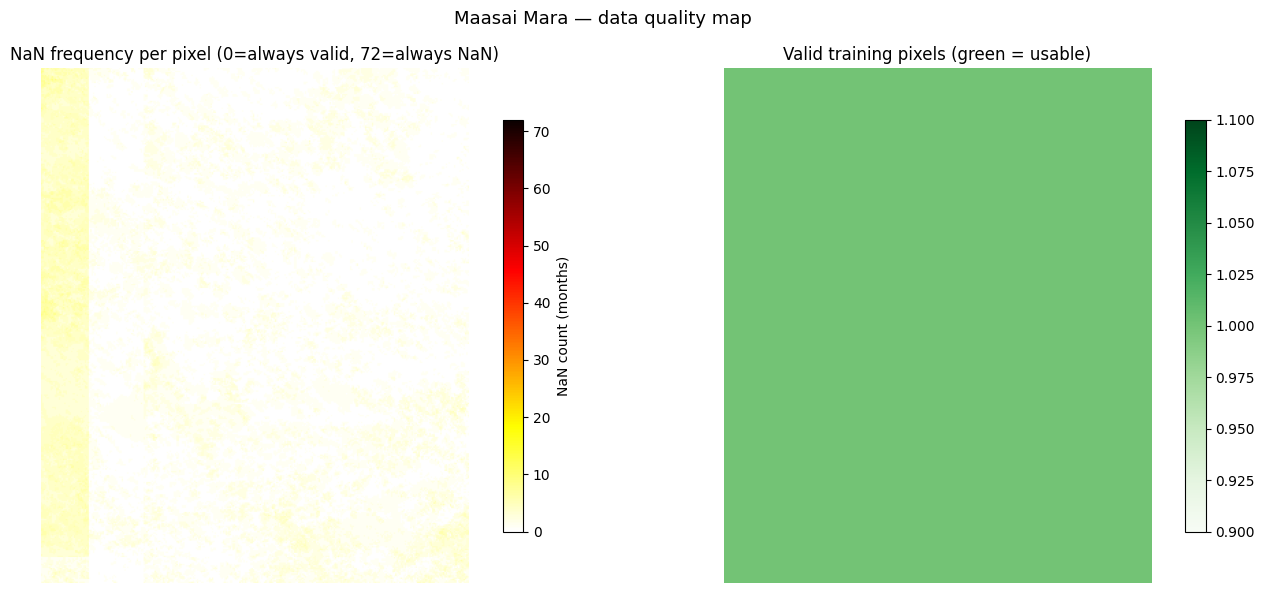

Saved valid_pixel_mask.npy


In [20]:
# Check NaN distribution across space and time
nan_per_pixel  = np.isnan(ndvi_filled).sum(axis=0)   # (H, W) — how often each pixel is NaN
nan_per_month  = np.isnan(ndvi_filled).sum(axis=(1,2)) # (T,)  — how many pixels NaN per month

print("Spatial NaN distribution:")
print(f"  Pixels never NaN:    {(nan_per_pixel == 0).sum():,}")
print(f"  Pixels always NaN:   {(nan_per_pixel == 72).sum():,}  <- permanent water/edge")
print(f"  Pixels sometimes NaN:{((nan_per_pixel > 0) & (nan_per_pixel < 72)).sum():,}")

print("\nMonths with most NaN pixels:")
top_nan_months = np.argsort(nan_per_month)[::-1][:5]
for idx in top_nan_months:
    print(f"  {dates_z[idx]}: {nan_per_month[idx]:,} NaN pixels "
          f"({nan_per_month[idx]/(H*W)*100:.1f}%)")

# Mask permanently NaN pixels — these are water/edge, exclude from training
permanent_nan_mask = nan_per_pixel == 72
valid_pixel_mask   = ~permanent_nan_mask

print(f"\nValid training pixels: {valid_pixel_mask.sum():,} "
      f"({valid_pixel_mask.sum()/(H*W)*100:.1f}% of AOI)")

# Plot NaN frequency map
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im1 = axes[0].imshow(nan_per_pixel, cmap='hot_r', vmin=0, vmax=72)
axes[0].set_title('NaN frequency per pixel (0=always valid, 72=always NaN)')
axes[0].axis('off')
plt.colorbar(im1, ax=axes[0], shrink=0.8, label='NaN count (months)')

im2 = axes[1].imshow(valid_pixel_mask, cmap='Greens')
axes[1].set_title('Valid training pixels (green = usable)')
axes[1].axis('off')
plt.colorbar(im2, ax=axes[1], shrink=0.8)

plt.suptitle('Maasai Mara — data quality map', fontsize=13)
plt.tight_layout()
plt.show()

# Save the valid pixel mask — needed for patch extraction in notebook 02
np.save('C:/vegformer/data/processed/valid_pixel_mask.npy', valid_pixel_mask)
print("Saved valid_pixel_mask.npy")

In [21]:
from scipy.interpolate import interp1d

def interpolate_full(array, dates):
    """
    Per-pixel linear interpolation across time.
    Handles scattered NaNs across the 66,754 sometimes-NaN pixels.
    array shape: (T, H, W)
    """
    T, H, W  = array.shape
    filled   = array.copy()
    t_index  = np.arange(T)
    fixed    = 0

    for r in range(H):
        for c in range(W):
            pixel = array[:, r, c]
            nan_mask   = np.isnan(pixel)
            valid_mask = ~nan_mask

            if nan_mask.any() and valid_mask.sum() >= 2:
                # Interpolate using valid timesteps
                f = interp1d(
                    t_index[valid_mask],
                    pixel[valid_mask],
                    kind='linear',
                    bounds_error=False,
                    fill_value=(pixel[valid_mask][0],
                                pixel[valid_mask][-1])
                )
                filled[nan_mask, r, c] = f(t_index[nan_mask])
                fixed += nan_mask.sum()

        if r % 50 == 0:
            print(f"  Row {r}/{H} processed...")

    print(f"  Fixed {fixed:,} NaN values across all pixels")
    return filled

print("Running full per-pixel interpolation...")
print("(This takes 2-3 minutes for 118,001 pixels)")
ndvi_final = interpolate_full(ndvi_filled, dates_z)

# Verify
print(f"\nFinal NaN count: {np.isnan(ndvi_final).sum()}")
print(f"Min NDVI: {ndvi_final.min():.3f}")
print(f"Max NDVI: {ndvi_final.max():.3f}")
print(f"Mean NDVI: {ndvi_final.mean():.3f}")

Running full per-pixel interpolation...
(This takes 2-3 minutes for 118,001 pixels)
  Row 0/377 processed...
  Row 50/377 processed...
  Row 100/377 processed...
  Row 150/377 processed...
  Row 200/377 processed...
  Row 250/377 processed...
  Row 300/377 processed...
  Row 350/377 processed...
  Fixed 126,821 NaN values across all pixels

Final NaN count: 0
Min NDVI: -0.046
Max NDVI: 0.930
Mean NDVI: 0.543


Saved clean array: 29.1 MB


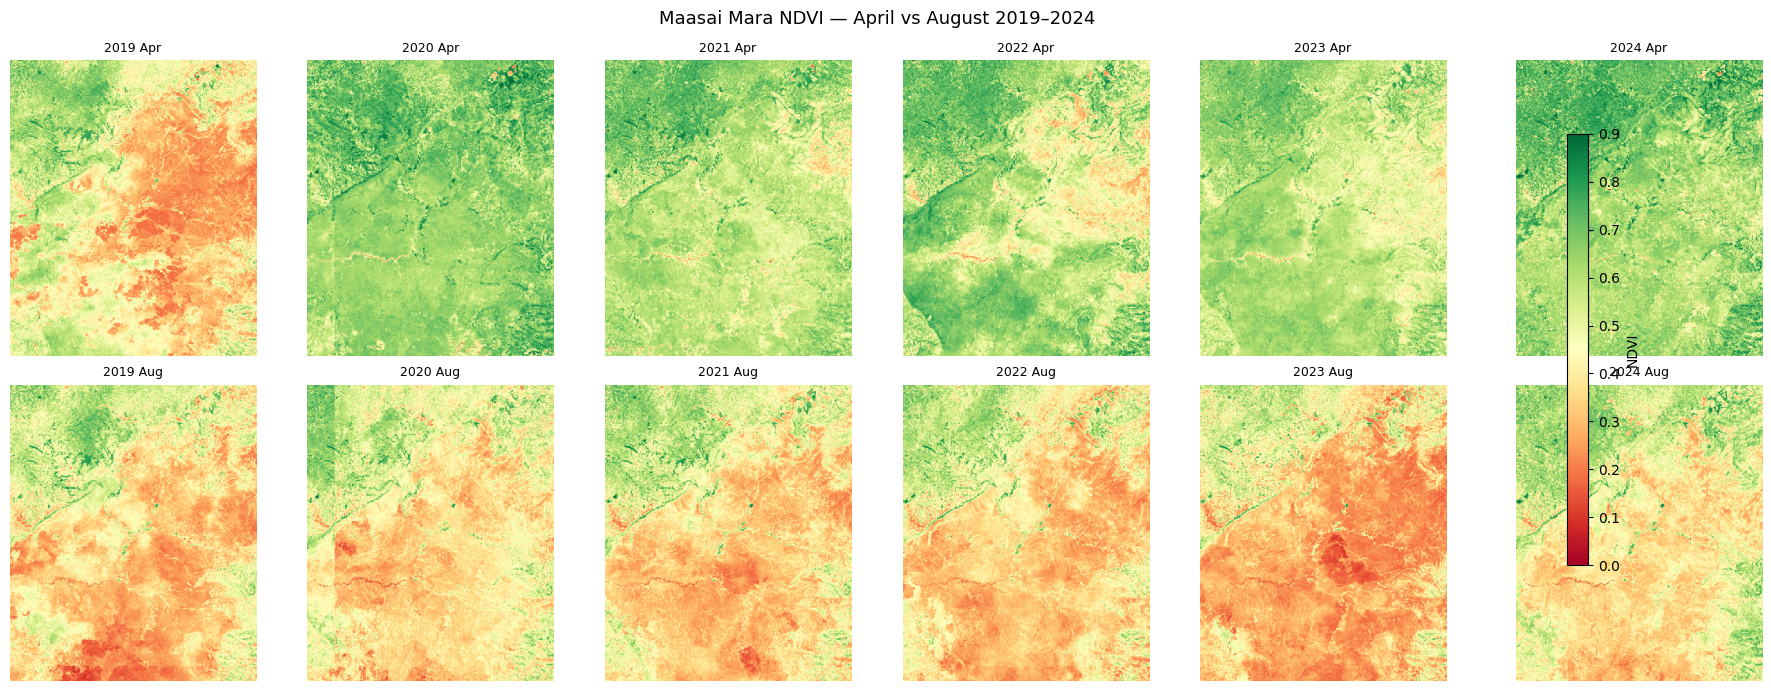


  Notebook 01 complete
  Pixels:      118,001
  Timesteps:   72 months (2019-01 to 2024-12)
  NaN values:  0
  File:        ndvi_monthly_2019_2024_clean.zarr
  Size:        29.1 MB
  Location:    C:\vegformer\data\processed

Ready for Notebook 02 — Sentinel-2 multi-band streaming


In [22]:
# Save final clean array
z_final = zarr.open(
    str(PROCESSED_DIR / 'ndvi_monthly_2019_2024_clean.zarr'),
    mode='w',
    shape=ndvi_final.shape,
    dtype='float32',
    chunks=(1, 377, 313),
)
z_final[:] = ndvi_final
z_final.attrs['dates']         = dates_z
z_final.attrs['aoi']           = 'Maasai Mara Ecosystem'
z_final.attrs['scale']         = '250m'
z_final.attrs['crs']           = 'EPSG:32736'
z_final.attrs['interpolated']  = True
z_final.attrs['nan_free']      = True
z_final.attrs['pixel_count']   = int(H * W)

size = sum(f.stat().st_size for f in 
           (PROCESSED_DIR / 'ndvi_monthly_2019_2024_clean.zarr').rglob('*'))
print(f"Saved clean array: {size/1e6:.1f} MB")

# Final visualization — 4 seasons across 6 years
fig, axes = plt.subplots(2, 6, figsize=(18, 7))

for col, year in enumerate(range(2019, 2025)):
    # Long rains (April)
    apr_idx = dates_z.index(f'{year}-04')
    im = axes[0, col].imshow(ndvi_final[apr_idx], 
                              cmap='RdYlGn', vmin=0, vmax=0.9)
    axes[0, col].set_title(f'{year} Apr', fontsize=9)
    axes[0, col].axis('off')

    # Dry season (August)
    aug_idx = dates_z.index(f'{year}-08')
    axes[1, col].imshow(ndvi_final[aug_idx], 
                         cmap='RdYlGn', vmin=0, vmax=0.9)
    axes[1, col].set_title(f'{year} Aug', fontsize=9)
    axes[1, col].axis('off')

axes[0, 0].set_ylabel('Long rains (Apr)', fontsize=9)
axes[1, 0].set_ylabel('Dry season (Aug)', fontsize=9)

plt.colorbar(im, ax=axes[:, -1], shrink=0.8, label='NDVI')
plt.suptitle('Maasai Mara NDVI — April vs August 2019–2024', fontsize=13)
plt.tight_layout()
plt.show()

# Summary of what we have
print("\n" + "="*50)
print("  Notebook 01 complete")
print("="*50)
print(f"  Pixels:      {H*W:,}")
print(f"  Timesteps:   72 months (2019-01 to 2024-12)")
print(f"  NaN values:  0")
print(f"  File:        ndvi_monthly_2019_2024_clean.zarr")
print(f"  Size:        {size/1e6:.1f} MB")
print(f"  Location:    {PROCESSED_DIR}")
print("="*50)
print("\nReady for Notebook 02 — Sentinel-2 multi-band streaming")